#### 5.1.2. Regresión supervisada

##### 5.1.2.1. Formulación y diseño del modelo

###### Formulación del problema

Se plantea un problema de **regresión supervisada**: estimar cuántos votos cambian entre el preconteo y el escrutinio en una mesa que fue corregida. La variable objetivo es `magnitud`, la suma de los cambios absolutos por candidatura, en el voto en blanco, en el nulo y en los no marcados, descontando el traslado de los votos de los candidatos retirados 009 y 013 al código 998.

Sea $\mathbf{x}_i \in \mathbb{R}^{26}$ el vector de variables de entrada de la mesa $i$ y $m_i$ su magnitud. Se busca una función

$$
f: \mathbb{R}^{26} \rightarrow \mathbb{R}, \qquad f(\mathbf{x}_i) \approx \log(1 + m_i)
$$

entrenada solo con las mesas corregidas ($m_i > 0$). La predicción en votos se obtiene con $\hat{m}_i = e^{f(\mathbf{x}_i)} - 1$.

###### Diseño en dos etapas

El 94,9 % de las mesas tiene magnitud 0. Una regresión entrenada con todas las mesas aprendería a predecir casi siempre cero y no distinguiría correcciones pequeñas de grandes. Por eso el problema se divide en dos etapas:

1. **Etapa 1, clasificación (5.1.1):** ¿la mesa será corregida?
2. **Etapa 2, regresión (esta sección):** si se corrige, ¿cuántos votos cambian?

La estimación final de una mesa combina las dos: magnitud esperada = probabilidad de corrección × magnitud estimada si se corrige. Esto permite priorizar no solo las mesas con más probabilidad de corrección, sino las que tienen más votos en juego.

###### Transformación de la variable objetivo

Entre las mesas corregidas, la magnitud es muy asimétrica: la mediana es de 3 votos y el máximo de 490. Si se modela directamente, las pocas correcciones grandes dominarían el ajuste. Por eso se modela $\log(1 + m)$ (`log1p`), que comprime la cola larga, y las predicciones se devuelven a votos con `expm1` para evaluarlas en unidades interpretables.

###### Selección y justificación de los modelos

| Modelo | Por qué se incluye | Hiperparámetros a explorar |
|---|---|---|
| **Regresión lineal con regularización (Ridge)** | Punto de partida interpretable. La regularización L2 controla la colinealidad entre los conteos de votos (total del preconteo, E-11, E-14 y votos en urna están muy correlacionados) | `alpha`: 0,1; 1; 10; 100 |
| **Random Forest** | Promedia muchos árboles de decisión: captura relaciones no lineales y umbrales (por ejemplo, "si la diferencia con el E-11 supera *k* votos"), es robusto a valores extremos y no requiere escalar las variables | `max_depth`: 6, 12, sin límite · `min_samples_leaf`: 5, 20 |
| **Gradient Boosting (HistGradientBoosting)** | Construye árboles de forma secuencial, cada uno corrigiendo el error de los anteriores. Suele ser el más preciso en datos tabulares y maneja valores faltantes sin imputar | `learning_rate`: 0,03; 0,1 · `max_leaf_nodes`: 15, 31 |

###### Variables de entrada

Se usan 26 variables, todas disponibles antes del escrutinio (lista `ENTRADAS`, definida más abajo). La más relevante es la diferencia entre el total del preconteo y los votantes del E-11 (`dif_pre_e11`, `abs_dif_pre_e11`): si el preconteo no cuadra con el número de votantes, es esperable que la corrección sea del tamaño de esa diferencia. `magnitud` y `y_corregida` no se usan como entrada.

###### Métricas y línea base

| Métrica | Qué mide |
|---|---|
| **MAE** (error absoluto medio, en votos) | Error promedio de la estimación; métrica principal por ser directamente interpretable |
| **RMSE** (raíz del error cuadrático medio, en votos) | Penaliza más los errores grandes; su diferencia con el MAE indica si hay errores grandes en pocas mesas |
| **R² en escala logarítmica** | Proporción de la variabilidad de `log1p(magnitud)` que explica el modelo |

**Línea base:** predecir para todas las mesas la mediana de la magnitud del entrenamiento. Un modelo útil debe tener un error claramente menor.

###### Diseño experimental

- **Entrenamiento:** mesas corregidas de los departamentos de entrenamiento.
- **Selección de hiperparámetros:** búsqueda en rejilla (`GridSearchCV`) con validación cruzada de 5 particiones agrupada por departamento (`GroupKFold`), minimizando el MAE en escala logarítmica.
- **Evaluación final:** una sola vez, sobre las mesas corregidas de los departamentos de prueba.
- **Preprocesamiento:** la imputación de vacíos (mediana) y el escalado (solo para Ridge) van dentro de un `Pipeline`, de modo que se ajustan únicamente con los datos de entrenamiento de cada partición.

##### 5.1.2.2. Carga del dataset de modelado

Se carga el dataset maestro construido en la sección 5.0, con las llaves de la mesa como texto para conservar los ceros a la izquierda. Se verifica que tenga las 40 columnas generadas en la sección 5.0.3; si se leyera una versión anterior (33 columnas), el notebook se detiene con un mensaje, en lugar de entrenar con variables incompletas.

In [194]:
import pandas as pd
from pathlib import Path

ruta = Path("../../data/processed/dataset_maestro.csv")

maestro = pd.read_csv(
    ruta,
    dtype={
        "dep": "string",
        "mun": "string",
        "zona": "string",
        "puesto": "string",
        "mesa": "string"
    }
)

print("Dimensiones:", maestro.shape)
print("Llaves duplicadas:", maestro.duplicated(
    ["dep", "mun", "zona", "puesto", "mesa"]
).sum())

assert maestro.shape[1] == 40, (
    f"El dataset tiene {maestro.shape[1]} columnas: ejecute primero la sección 5.0.3"
)
maestro.head()

Dimensiones: (118350, 40)
Llaves duplicadas: 0


,dep,mun,zona,puesto,mesa,total_votos_preconteo,numero_registros,opciones_reportadas,votos_blancos,votos_nulos,...,votos_incinerados,sufragantes_e11_segun_e14,total_votos_novedades,tasa_retirados,hhi,dif_pre_e11,abs_dif_pre_e11,dif_e14_e11,dif_urna_e11,participacion_e11
0,01,001,001,01,000001,127,16,16,3,0,...,0,128,127,0.0,0.339547,-1.0,1.0,0,0,0.355556
1,01,001,001,01,000002,65,16,16,3,0,...,0,65,65,0.0,0.503122,0.0,0.0,0,0,0.180556
2,01,001,001,01,000003,107,16,16,0,2,...,0,107,107,0.0,0.297234,0.0,0.0,0,0,0.297222
3,01,001,001,01,000004,143,16,16,3,2,...,0,143,143,0.0,0.352132,0.0,0.0,0,0,0.397222
4,01,001,001,01,000005,177,16,16,3,4,...,0,177,177,0.0,0.371801,0.0,0.0,0,0,0.491667


##### 5.1.2.3. Preparación de los datos y partición

La siguiente celda prepara los datos del modelado. Las variables que define (`X`, `y`, `grupos`, `idx_tr`, `idx_te` y `CV`) son comunes a los tres componentes del proyecto, para que todos entrenen con las mismas variables y se evalúen sobre las mismas mesas.

**1. Conversión de las banderas.** `tachaduras_enmendaduras` y `recontada_jurados` vienen como texto (`SI` / `NO`) y se convierten a 1 / 0, porque los modelos de scikit-learn solo aceptan valores numéricos.

**2. Selección de las variables de entrada.** Se define de forma explícita la lista `ENTRADAS` con las 26 variables que puede usar el modelo, todas disponibles **antes** del escrutinio. El dataset maestro conserva el resto de columnas como referencia, pero estas no entran al modelo:

| Columnas excluidas | Razón |
|---|---|
| `total_votos_novedades`, `recontada_comision`, `excluida`, `estado_sobre`, `en_terminos` | **Fuga de información:** se registran durante el escrutinio. `total_votos_novedades` es igual al total del escrutinio, y el 100 % de las mesas excluidas y el 89 % de las recontadas por la comisión fueron corregidas |
| `numero_registros`, `opciones_reportadas` | Describen el formato de transmisión del preconteo, que depende del departamento, y no una característica de la mesa |
| `dep`, `mun`, `zona`, `puesto`, `mesa` | Identifican la mesa; se conservan para unir resultados y para agrupar por departamento |
| `y_corregida`, `magnitud` | Son las variables objetivo |

**3. Partición en entrenamiento y prueba por departamento.** No se usa una partición aleatoria por mesa (`train_test_split`), porque las mesas de un mismo departamento comparten la comisión escrutadora, el formato de transmisión del preconteo y una tasa de corrección propia (entre 2,6 % y 8,9 % según el departamento). Si mesas del mismo departamento quedaran en entrenamiento y en prueba, el modelo podría acertar por reconocer el territorio y la evaluación sería optimista.

Por eso se usa `GroupShuffleSplit`, que reserva para prueba el **25 % de los departamentos completos**. El modelo nunca ve esas mesas durante el entrenamiento, así que la prueba mide su capacidad de generalizar a departamentos nuevos. Se fija `random_state=0` para que la partición sea la misma cada vez que se ejecuta el notebook. Como `GroupShuffleSplit` está pensado para generar varias particiones, devuelve un generador; con `next()` se toma la única partición solicitada (`n_splits=1`). El resultado son los índices de fila de cada conjunto (`idx_tr`, `idx_te`).

**4. Validación cruzada agrupada.** Se define `GroupKFold` con 5 particiones, que se usa en la búsqueda de hiperparámetros dentro del entrenamiento: el entrenamiento se divide en 5 grupos de departamentos y cada configuración se entrena 5 veces, validando cada vez con un grupo distinto. Así se eligen los hiperparámetros sin usar la partición de prueba, y con el mismo criterio de departamentos no vistos que la evaluación final.

**5. Verificación de la partición.** Al final se construye una tabla resumen que describe los dos conjuntos: número de mesas, de departamentos y de mesas corregidas, y el porcentaje de corregidas (el promedio de `y_corregida`, que vale 1 o 0). Esta verificación es necesaria porque la partición por departamentos no puede estratificarse por la variable objetivo; la tabla permite comprobar que la proporción de mesas corregidas es similar en ambos conjuntos.

In [195]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

LLAVE = ["dep", "mun", "zona", "puesto", "mesa"]
df = maestro.copy()

for col in ["tachaduras_enmendaduras", "recontada_jurados"]:
    df[col] = df[col].eq("SI").astype(int)

# Se excluyen por fuga: total_votos_novedades, recontada_comision, excluida, estado_sobre, en_terminos
# Se excluyen por describir el formato de transmisión: numero_registros, opciones_reportadas
ENTRADAS = [
    "total_votos_preconteo", "votos_blancos", "votos_nulos", "votos_no_marcados",
    "proporcion_blancos", "proporcion_nulos", "proporcion_no_marcados",
    "margen_primero_segundo", "concentracion_maxima", "sin_votos_preconteo",
    "e11_sospechoso", "potencial", "sufragantes_e11", "tachaduras_enmendaduras",
    "recontada_jurados", "firmas_jurados", "votos_urna", "votos_incinerados",
    "sufragantes_e11_segun_e14", "tasa_retirados", "hhi",
    "dif_pre_e11", "abs_dif_pre_e11", "dif_e14_e11", "dif_urna_e11", "participacion_e11",
]
X, y, grupos = df[ENTRADAS], df["y_corregida"], df["dep"]

# Partición común: 25 % de los departamentos para prueba
idx_tr, idx_te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
                      .split(X, y, grupos))
CV = GroupKFold(n_splits=5)

particion = pd.DataFrame({
    "mesas": [len(idx_tr), len(idx_te)],
    "departamentos": [grupos.iloc[idx_tr].nunique(), grupos.iloc[idx_te].nunique()],
    "mesas corregidas": [int(y.iloc[idx_tr].sum()), int(y.iloc[idx_te].sum())],
    "% corregidas": [round(y.iloc[idx_tr].mean() * 100, 2), round(y.iloc[idx_te].mean() * 100, 2)],
}, index=["entrenamiento", "prueba"])
display(particion)
print("Departamentos de prueba:", sorted(grupos.iloc[idx_te].unique()))

,mesas,departamentos,mesas corregidas,% corregidas
entrenamiento,85994,24,4292,4.99
prueba,32356,9,1706,5.27


Departamentos de prueba: ['05', '17', '19', '26', '27', '31', '48', '50', '52']


**Lectura:** la partición deja 85 994 mesas para entrenamiento (24 departamentos) y 32 356 para prueba (9 departamentos: 05, 17, 19, 26, 27, 31, 48, 50 y 52). Como se reparten departamentos y no mesas, la prueba tiene el 27 % de las mesas y no exactamente el 25 %. La proporción de mesas corregidas es similar en ambos conjuntos (4,99 % en entrenamiento y 5,27 % en prueba), por lo que la prueba es representativa aunque la partición no se haya estratificado.

##### 5.1.2.4. Datos de la regresión: mesas corregidas

La regresión se entrena y evalúa solo con las mesas corregidas (`y_corregida = 1`), respetando la misma partición por departamentos. Se cruzan los índices de entrenamiento y prueba con los de las mesas corregidas, y se definen:

- `Xr_tr`, `Xr_te`: las 26 variables de entrada de las mesas corregidas de cada conjunto.
- `yr_tr`: el objetivo de entrenamiento, `log1p(magnitud)`.
- `yr_te`: el objetivo de prueba **en votos**, porque la evaluación se reporta en votos después de deshacer la transformación.
- `gr_tr`: el departamento de cada mesa de entrenamiento, para la validación cruzada agrupada.

Los histogramas comparan la distribución de la magnitud en votos y en escala `log1p`.

Mesas corregidas: 4,292 en entrenamiento | 1,706 en prueba


,magnitud (votos)
count,5998.00
mean,13.14
std,34.12
min,1.00
25%,1.00
50%,3.00
75%,8.00
max,490.00


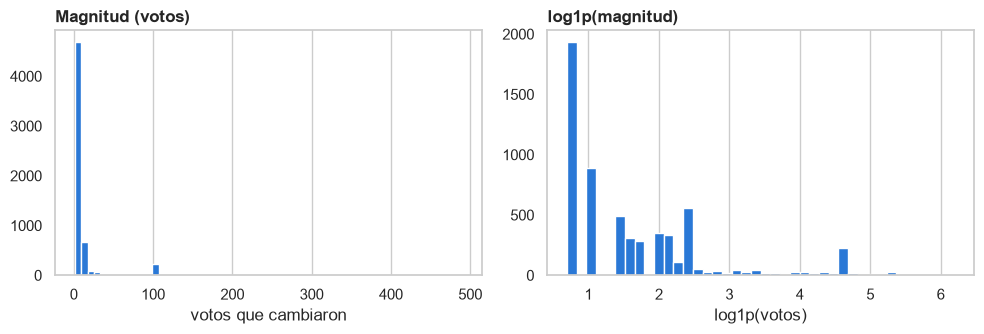

In [196]:
corr = (df["y_corregida"] == 1).to_numpy()
tr_corr = np.intersect1d(idx_tr, np.where(corr)[0])
te_corr = np.intersect1d(idx_te, np.where(corr)[0])

Xr_tr, Xr_te = X.iloc[tr_corr], X.iloc[te_corr]
yr_tr = np.log1p(df["magnitud"].iloc[tr_corr])        # objetivo en escala log
yr_te = df["magnitud"].iloc[te_corr].to_numpy()       # en votos, para evaluar
gr_tr = grupos.iloc[tr_corr]

print(f"Mesas corregidas: {len(tr_corr):,} en entrenamiento | {len(te_corr):,} en prueba")
display(df.loc[corr, "magnitud"].describe().round(2).to_frame("magnitud (votos)"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df.loc[corr, "magnitud"], bins=60, color="#2a78d6")
axes[0].set_title("Magnitud (votos)"); axes[0].set_xlabel("votos que cambiaron")
axes[1].hist(np.log1p(df.loc[corr, "magnitud"]), bins=40, color="#2a78d6")
axes[1].set_title("log1p(magnitud)"); axes[1].set_xlabel("log1p(votos)")
plt.tight_layout(); plt.show()

**Lectura:** la regresión se entrena con 4 292 mesas corregidas de los departamentos de entrenamiento y se evalúa con 1 706 de los departamentos de prueba. La magnitud está muy concentrada en valores pequeños: en 1 933 mesas (32 %) cambió un solo voto, la mitad de las correcciones es de 3 votos o menos y el 75 % de 8 o menos, con una cola larga que llega hasta 490 votos (media de 13,1 votos frente a una mediana de 3). En escala `log1p` la distribución queda más repartida, lo que justifica entrenar el modelo en esa escala para que las pocas correcciones grandes no dominen el ajuste.

Destacan dos picos: 555 mesas con exactamente 10 votos de diferencia (frente a 108 con 9 y 30 con 11) y 201 con exactamente 100. Este patrón es consistente con errores de digitación en el preconteo, donde un dígito equivocado en las decenas o centenas produce diferencias de 10 o 100 votos que el escrutinio corrige. No puede confirmarse sin los formularios físicos, pero indica que una parte de las correcciones responde a errores de transcripción y no a cambios en la votación.

#### 5.2.2. Regresión supervisada

##### 5.2.2.1. Búsqueda de hiperparámetros

Se entrenan los tres modelos de regresión con las 4 292 mesas corregidas del entrenamiento, con objetivo `log1p(magnitud)`. Los hiperparámetros se eligen con búsqueda en rejilla (`GridSearchCV`): para cada combinación se entrena el modelo con validación cruzada de 5 particiones agrupada por departamento (`GroupKFold`) y se calcula el error absoluto medio (MAE) promedio. Se elige la combinación con menor MAE, y `GridSearchCV` reentrena ese modelo con todo el entrenamiento.

El dataset conserva vacía la diferencia preconteo − E-11 en las 145 mesas con E-11 sospechoso, como se decidió en la Fase 3, y las variables de composición del voto en las 6 mesas sin votos en el preconteo. Como la regresión lineal y el Random Forest no admiten valores vacíos, dentro del `Pipeline` se rellenan con la mediana del entrenamiento; la bandera `e11_sospechoso` se mantiene como variable de entrada para que el modelo distinga esas mesas. El Gradient Boosting maneja los vacíos de forma nativa y no requiere imputación.

In [197]:
from sklearn.model_selection import GridSearchCV, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

regresores = {
    "Regresión lineal (Ridge)": (
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100]}),
    "Random Forest": (
        make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)),
        {"randomforestregressor__max_depth": [6, 12, None],
         "randomforestregressor__min_samples_leaf": [5, 20]}),
    "Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=0),
        {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31]}),
}

busq_reg, filas = {}, []
for nombre, (modelo, rejilla) in regresores.items():
    gs = GridSearchCV(modelo, rejilla, scoring="neg_mean_absolute_error", cv=CV)
    gs.fit(Xr_tr, yr_tr, groups=gr_tr)
    busq_reg[nombre] = gs
    for params, media, desv in zip(gs.cv_results_["params"],
                                   gs.cv_results_["mean_test_score"],
                                   gs.cv_results_["std_test_score"]):
        filas.append({"modelo": nombre,
                      "hiperparámetros": {k.split("__")[-1]: v for k, v in params.items()},
                      "MAE log1p (CV)": -media,
                      "desv. estándar": desv})

tabla_rejilla = pd.DataFrame(filas).sort_values("MAE log1p (CV)").reset_index(drop=True)
display(tabla_rejilla.round(3))

mejores = tabla_rejilla.groupby("modelo").first().sort_values("MAE log1p (CV)")
MEJOR_REG = mejores.index[0]
print("Mejor configuración de cada modelo:")
display(mejores.round(3))
print("Modelo elegido:", MEJOR_REG)

,modelo,hiperparámetros,MAE log1p (CV),desv. estándar
0,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5}",0.187,0.019
1,Random Forest,"{'max_depth': 6, 'min_samples_leaf': 5}",0.188,0.020
2,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.189,0.019
3,Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.190,0.017
4,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 20}",0.201,0.014
5,Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.201,0.017
6,Random Forest,"{'max_depth': None, 'min_samples_leaf': 20}",0.201,0.014
7,Random Forest,"{'max_depth': 6, 'min_samples_leaf': 20}",0.201,0.015
8,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}",0.209,0.013
9,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15}",0.210,0.011


Mejor configuración de cada modelo:


,hiperparámetros,MAE log1p (CV),desv. estándar
modelo,,,
Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5}",0.187,0.019
Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.190,0.017
Regresión lineal (Ridge),{'alpha': 0.1},0.583,0.012


Modelo elegido: Random Forest


##### 5.2.2.2. Comparación de los modelos

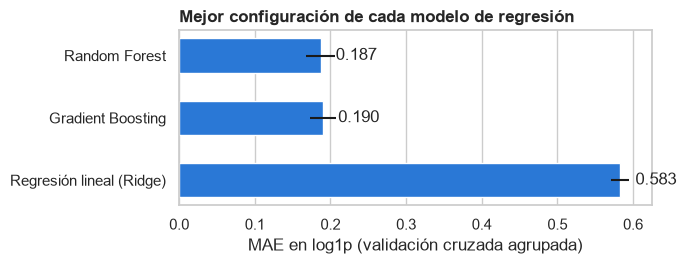

In [198]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(mejores.index[::-1], mejores["MAE log1p (CV)"][::-1],
        xerr=mejores["desv. estándar"][::-1], color="#2a78d6", height=0.55)
for i, v in enumerate(mejores["MAE log1p (CV)"][::-1]):
    ax.text(v + 0.02, i, f"{v:.3f}", va="center")
ax.set_xlabel("MAE en log1p (validación cruzada agrupada)")
ax.set_title("Mejor configuración de cada modelo de regresión")
plt.tight_layout(); plt.show()

**¿Qué significa un MAE de 0,187 y de 0,190?**

El MAE de la gráfica está en escala logarítmica, porque los modelos se entrenan con $\log(1 + \text{magnitud})$. Por eso no se lee directamente en votos: mide en promedio cuánto se aleja la predicción del valor real **en términos relativos**.

Un error de $d$ en escala logarítmica significa que la predicción se aleja del valor real por un factor de $e^{d}$:

$$
|\log(1 + \hat{m}) - \log(1 + m)| = d \quad \Longleftrightarrow \quad \frac{1 + \hat{m}}{1 + m} = e^{d} \ \text{ o } \ e^{-d}
$$

| Modelo | MAE (log1p) | Factor $e^{d}$ | Error relativo típico | Ejemplo: mesa con 10 votos de cambio |
|---|---|---|---|---|
| Random Forest | 0,187 | 1,21 | ≈ 21 % | predice entre 8 y 12 votos |
| Gradient Boosting | 0,190 | 1,21 | ≈ 21 % | predice entre 8 y 12 votos |
| Regresión lineal (Ridge) | 0,583 | 1,79 | ≈ 79 % | predice entre 5 y 19 votos |

En otras palabras, el Random Forest y el Gradient Boosting se equivocan en promedio alrededor de un 21 % del valor real de la magnitud, mientras que la regresión lineal se equivoca cerca de un 79 %. La diferencia entre 0,187 y 0,190 equivale a menos de medio punto porcentual de error relativo y es menor que la variación entre particiones (barras negras), así que en la práctica los dos modelos de árboles tienen el mismo desempeño.

Al ser un error relativo, su tamaño en votos depende del tamaño de la corrección: en una mesa que cambió 2 votos, un 21 % es menos de un voto, y en una que cambió 100 votos son unos 20 votos. El error promedio en votos se reporta en la evaluación sobre la partición de prueba (sección 5.3.2).

##### 5.2.2.3. Curva de validación del Random Forest

Para analizar el efecto del hiperparámetro principal del modelo elegido, se calcula el MAE de entrenamiento y de validación (con la misma validación cruzada agrupada por departamento) para distintas profundidades máximas de los árboles (`max_depth`). Un árbol poco profundo hace pocas preguntas y puede ser demasiado simple (subajuste); uno muy profundo puede memorizar los datos de entrenamiento (sobreajuste). Para que el cálculo sea más rápido, la curva usa 100 árboles en lugar de 200.

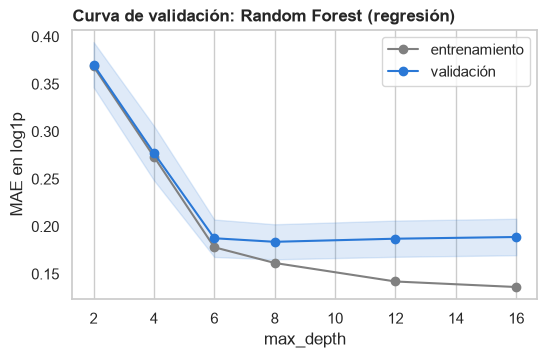

,max_depth,MAE entrenamiento,MAE validación
0,2,0.368,0.370
1,4,0.274,0.277
2,6,0.178,0.188
3,8,0.162,0.184
4,12,0.142,0.187
5,16,0.136,0.189


In [199]:
profundidades = [2, 4, 6, 8, 12, 16]
rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                         n_jobs=-1, random_state=0))
tr_sc, va_sc = validation_curve(rf, Xr_tr, yr_tr, groups=gr_tr, cv=CV,
                                param_name="randomforestregressor__max_depth",
                                param_range=profundidades,
                                scoring="neg_mean_absolute_error")

plt.figure(figsize=(6, 3.5))
plt.plot(profundidades, -tr_sc.mean(1), "o-", color="gray", label="entrenamiento")
plt.plot(profundidades, -va_sc.mean(1), "o-", color="#2a78d6", label="validación")
plt.fill_between(profundidades, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1),
                 color="#2a78d6", alpha=0.15)
plt.xlabel("max_depth"); plt.ylabel("MAE en log1p")
plt.title("Curva de validación: Random Forest (regresión)"); plt.legend(); plt.show()

display(pd.DataFrame({"max_depth": profundidades,
                      "MAE entrenamiento": -tr_sc.mean(1),
                      "MAE validación": -va_sc.mean(1)}).round(3))

**Lectura:** con árboles poco profundos (profundidad 2) el error es alto y casi igual en entrenamiento y en validación (0,368 y 0,370): el modelo es demasiado simple para capturar la relación (subajuste). Al aumentar la profundidad, el error de validación baja rápidamente hasta estabilizarse entre las profundidades 6 y 8, donde alcanza su mínimo (MAE = 0,184 con profundidad 8). A partir de ahí el error de entrenamiento sigue bajando (0,142 con profundidad 12 y 0,136 con 16), pero el de validación ya no mejora e incluso sube levemente (0,187 y 0,189). La brecha entre ambos errores pasa de 0,002 a 0,053: los árboles más profundos memorizan las mesas de entrenamiento sin ganar capacidad para generalizar a departamentos no vistos (sobreajuste).

La búsqueda en rejilla eligió `max_depth = 12` porque la rejilla solo incluía 6, 12 y sin límite; la curva muestra que una profundidad de 8 daría prácticamente el mismo error (0,184 frente a 0,187). La diferencia es menor que la variación entre particiones (desviación ≈ 0,02), por lo que la elección de 12 no afecta el desempeño de forma apreciable.

#### 5.3.2. Regresión supervisada

##### 5.3.2.1. Métricas en la partición de prueba

Se evalúan los tres modelos, con los hiperparámetros elegidos en la sección 5.2.2 y reentrenados con todo el entrenamiento, sobre las 1 706 mesas corregidas de los 9 departamentos de prueba. Las predicciones se devuelven de la escala `log1p` a votos con `expm1`, de modo que el error se reporta en votos. Se comparan con la línea base, que predice para todas las mesas la mediana de la magnitud del entrenamiento.

In [200]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

filas, preds_reg = [], {}
for nombre, gs in busq_reg.items():
    pred = np.clip(np.expm1(gs.predict(Xr_te)), 0, None)    # de vuelta a votos
    preds_reg[nombre] = pred
    filas.append({"modelo": nombre,
                  "MAE (votos)": mean_absolute_error(yr_te, pred),
                  "RMSE (votos)": mean_squared_error(yr_te, pred) ** 0.5,
                  "R² (log1p)": r2_score(np.log1p(yr_te), np.log1p(pred))})

mediana = np.expm1(yr_tr).median()
base = np.full(len(yr_te), mediana)
filas.append({"modelo": f"Línea base: mediana ({mediana:.0f} votos)",
              "MAE (votos)": mean_absolute_error(yr_te, base),
              "RMSE (votos)": mean_squared_error(yr_te, base) ** 0.5,
              "R² (log1p)": r2_score(np.log1p(yr_te), np.log1p(base))})

tabla_reg_te = pd.DataFrame(filas).set_index("modelo")
display(tabla_reg_te.round(3))
print(f"Mesas corregidas evaluadas: {len(yr_te):,}")

,MAE (votos),RMSE (votos),R² (log1p)
modelo,,,
Regresión lineal (Ridge),9.295,69.009,0.529
Random Forest,3.211,20.188,0.779
Gradient Boosting,3.511,20.683,0.771
Línea base: mediana (3 votos),10.798,33.085,-0.043


Mesas corregidas evaluadas: 1,706


**Métricas de evaluación de la regresión**

Como la regresión predice un número (cuántos votos cambian) y no una categoría, no se evalúa con métricas de clasificación como *accuracy* o *recall*, que cuentan aciertos y errores. En regresión importa **qué tan lejos** queda la predicción del valor real, y para eso se usan tres métricas complementarias:

| Métrica | Qué mide | Cómo se interpreta |
|---|---|---|
| **MAE** (error absoluto medio) | Promedio de la diferencia, en valor absoluto, entre los votos reales y los predichos | Cuántos votos se equivoca el modelo en promedio. Es la métrica principal por ser directamente interpretable |
| **RMSE** (raíz del error cuadrático medio) | Similar al MAE, pero eleva los errores al cuadrado antes de promediar | Castiga más los errores grandes. Si el RMSE es mucho mayor que el MAE, hay pocas mesas con errores muy grandes |
| **R²** (en escala `log1p`) | Proporción de la variabilidad de la magnitud que explica el modelo | 1 = predicción perfecta; 0 = no mejora a predecir un valor constante; negativo = peor que un valor constante |

**Resultados en la partición de prueba (1 706 mesas corregidas de 9 departamentos no vistos)**

| Modelo | MAE (votos) | RMSE (votos) | R² (log1p) |
|---|---|---|---|
| **Random Forest** | **3,21** | **20,19** | **0,779** |
| Gradient Boosting | 3,51 | 20,68 | 0,771 |
| Regresión lineal (Ridge) | 9,30 | 69,01 | 0,529 |
| Línea base: mediana (3 votos) | 10,80 | 33,09 | −0,043 |

**Lectura:**

- **El Random Forest es el mejor modelo.** Se equivoca en promedio 3,2 votos por mesa, frente a 10,8 votos de la línea base que predice siempre la mediana: reduce el error en un 70 %. Explica cerca del 78 % de la variabilidad de la magnitud (R² = 0,779).
- **El Gradient Boosting queda muy cerca** (3,5 votos; R² = 0,771). Los dos modelos de árboles tienen un desempeño equivalente, igual que en la validación cruzada, y mantienen ese desempeño en departamentos que no vieron durante el entrenamiento.
- **La regresión lineal es casi tan mala como la línea base** (9,3 votos) y su RMSE (69 votos) es incluso el doble que el de la mediana: en algunas mesas comete errores muy grandes. Esto confirma que la relación entre las

##### 5.3.2.2. Error según el tamaño de la corrección

In [203]:
pred_mejor = preds_reg[MEJOR_REG]
rangos = pd.cut(yr_te, [0, 2, 5, 20, 100, 1000],
                labels=["1-2", "3-5", "6-20", "21-100", "más de 100"])
por_rango = (pd.DataFrame({"rango (votos)": rangos,
                           "error": np.abs(yr_te - pred_mejor),
                           "base": np.abs(yr_te - base)})
             .groupby("rango (votos)", observed=True)
             .agg(mesas=("error", "size"),
                  **{"MAE modelo": ("error", "mean"), "MAE mediana": ("base", "mean")}))
display(por_rango.round(2))

,mesas,MAE modelo,MAE mediana
rango (votos),,,
1-2,840,0.68,1.69
3-5,322,0.56,0.77
6-20,384,1.12,5.77
21-100,124,10.30,69.60
más de 100,36,83.83,164.03


**Error según el tamaño de la corrección**

La tabla agrupa las 1 706 mesas corregidas de prueba según cuántos votos cambiaron realmente entre el preconteo y el escrutinio, y compara en cada grupo el error absoluto medio (MAE) del Random Forest con el de la línea base, que predice siempre la mediana (3 votos).

| Rango real (votos) | Mesas | % de las mesas | MAE modelo (votos) | MAE mediana (votos) |
|---|---|---|---|---|
| 1 – 2 | 840 | 49 % | 0,68 | 1,69 |
| 3 – 5 | 322 | 19 % | 0,56 | 0,77 |
| 6 – 20 | 384 | 23 % | 1,12 | 5,77 |
| 21 – 100 | 124 | 7 % | 10,30 | 69,60 |
| Más de 100 | 36 | 2 % | 83,83 | 164,03 |


- **Correcciones pequeñas (1 a 5 votos).** Son 1 162 mesas, el 68 % de la prueba. El modelo se equivoca en promedio menos de un voto (0,68 y 0,56), es decir, casi siempre acierta el número exacto o queda a un voto.
- **Correcciones medianas (6 a 20 votos).** En estas 384 mesas el error es de 1,1 votos, frente a 5,8 de la línea base: el modelo es cinco veces más preciso.
- **Correcciones grandes (más de 20 votos).** El error crece: unos 10 votos en las mesas de 21 a 100 y unos 84 en las de más de 100. Aun así, el modelo sigue siendo mucho mejor que la mediana (70 y 164 votos).
- **El modelo supera a la línea base en todos los rangos.** La diferencia más pequeña está en el rango de 3 a 5 votos (0,56 frente a 0,77), porque la mediana (3 votos) cae justo dentro de ese rango.
- **Pocas mesas concentran la mayor parte del error.** Las 36 mesas con correcciones de más de 100 votos son solo el 2 % de la prueba, pero aportan cerca del 55 % del error total (36 × 83,8 ≈ 3 018 votos de un total de 1 706 × 3,21 ≈ 5 478). Esto explica por qué el RMSE (20,2 votos) es mucho mayor que el MAE (3,2 votos).

En conclusión, el modelo es muy preciso en la gran mayoría de las mesas, que tienen correcciones pequeñas o medianas, y pierde precisión en unas pocas correcciones excepcionales, que además son las menos representadas en los datos de entrenamiento.

##### 5.3.2.3. Valores reales frente a predichos

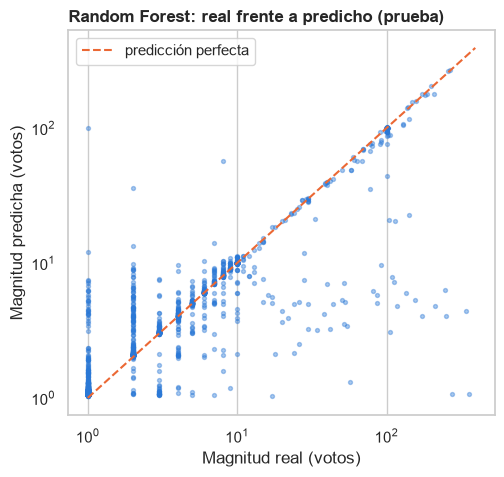

In [204]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(yr_te, pred_mejor, s=8, alpha=0.4, color="#2a78d6")
lim = [1, max(yr_te.max(), pred_mejor.max()) * 1.1]
ax.plot(lim, lim, "--", color="#eb6834", label="predicción perfecta")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Magnitud real (votos)"); ax.set_ylabel("Magnitud predicha (votos)")
ax.set_title(f"{MEJOR_REG}: real frente a predicho (prueba)"); ax.legend()
plt.show()

**Lectura:** cada punto es una mesa corregida de prueba; el eje horizontal muestra la magnitud real y el vertical la predicha por el Random Forest, ambos en escala logarítmica. La línea naranja representa la predicción perfecta.

La mayoría de los puntos se ubica sobre la diagonal o muy cerca de ella, en todos los tamaños de corrección, incluidas correcciones de 100 a 300 votos que el modelo estima casi exactamente. Estas son, probablemente, las mesas en las que la diferencia entre el total del preconteo y el E-11 coincide con el tamaño de la corrección, que es la señal principal que aprende el modelo. En las correcciones pequeñas (1 a 5 votos) las predicciones forman columnas verticales, porque la magnitud real es entera, y se dispersan poco alrededor del valor real.

El error grande se concentra en un grupo de mesas por debajo de la diagonal: correcciones reales de entre 10 y 300 votos para las que el modelo predice solo entre 2 y 10. Una explicación probable es que en esas mesas el escrutinio redistribuyó votos entre candidaturas sin cambiar el total, de modo que el preconteo sí coincide con el E-11 y el modelo no dispone de una señal que anticipe la corrección. Unos pocos puntos por encima de la diagonal corresponden a sobreestimaciones, posiblemente mesas con una diferencia grande respecto al E-11 originada en un error del propio formulario. Estas mesas mal estimadas son pocas, pero explican la diferencia entre el RMSE (20,2 votos) y el MAE (3,2 votos).

##### 5.3.2.4. Importancia de las variables

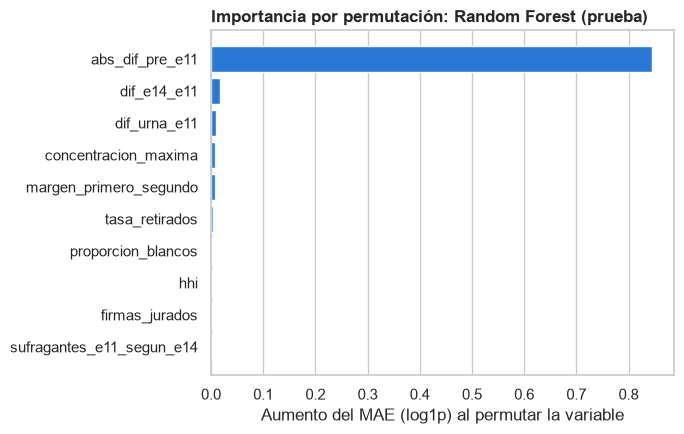

In [205]:
from sklearn.inspection import permutation_importance

mejor_reg = busq_reg[MEJOR_REG].best_estimator_
imp = permutation_importance(mejor_reg, Xr_te, np.log1p(yr_te),
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
importancias = pd.Series(imp.importances_mean, index=ENTRADAS).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importancias.index[-10:], importancias.values[-10:], color="#2a78d6")
ax.set_xlabel("Aumento del MAE (log1p) al permutar la variable")
ax.set_title(f"Importancia por permutación: {MEJOR_REG} (prueba)")
plt.tight_layout(); plt.show()

**Importancia de las variables (permutación)**

La importancia por permutación mide cuánto empeora el modelo cuando se desordena al azar una variable en los datos de prueba, rompiendo su relación con la magnitud: si el error aumenta mucho, el modelo depende de esa variable; si no cambia, el modelo casi no la usa.

la diferencia absoluta entre el total del preconteo y los votantes del E-11 (`abs_dif_pre_e11`) domina por completo: al desordenarla, el MAE en escala logarítmica aumenta en 0,84, es decir, pasa de un error de alrededor del 20 % a uno de casi tres veces el valor real. Las variables de consistencia entre los formularios de la mesa (`dif_e14_e11`, `dif_urna_e11`) y las de composición del voto (`concentracion_maxima`, `margen_primero_segundo`, `tasa_retirados`) aportan ajustes pequeños, y el resto prácticamente no influye.

Esto indica que el tamaño de una corrección está ligado sobre todo al tamaño de la inconsistencia entre el preconteo y el número de votantes registrado en la mesa, y explica el patrón de la gráfica anterior: el modelo acierta cuando esa diferencia refleja la corrección y subestima las correcciones que redistribuyen votos entre candidaturas sin cambiar el total, porque en esas mesas la diferencia con el E-11 es nula. La variable con signo `dif_pre_e11` no aparece entre las más importantes porque contiene casi la misma información que su valor absoluto; la importancia por permutación tiende a subestimar variables muy correlacionadas entre sí.

##### 5.3.2.5. Resumen de la evaluación de la regresión

En los 9 departamentos de prueba, el Random Forest estima la magnitud de la corrección con un error absoluto medio de **3,2 votos**, frente a **10,8 votos** de la línea base que predice siempre la mediana, y explica cerca del **78 %** de la variabilidad de la magnitud en escala logarítmica (R² = 0,779). El Gradient Boosting queda muy cerca (**3,5 votos**) y la regresión lineal muy por detrás (**9,3 votos**), lo que confirma lo observado en la validación cruzada.

El RMSE (**20,2 votos**) es mucho mayor que el MAE: el modelo acierta bien las correcciones pequeñas, que son la mayoría, y se equivoca más en las pocas correcciones grandes. La tabla por rangos lo muestra: en las mesas con 1 a 5 votos de cambio el error es de **menos de un voto** (0,68 y 0,56), mientras que en las 36 mesas con más de 100 votos llega a **84 votos**. En la gráfica de valores reales frente a predichos, la mayoría de los puntos se concentra sobre la diagonal, y los errores grandes corresponden a un grupo de correcciones grandes que el modelo subestima.

La importancia por permutación muestra que la variable que más pesa es la diferencia entre el total del preconteo y el E-11 (`abs_dif_pre_e11`): el tamaño de la corrección está ligado al tamaño de la inconsistencia entre el preconteo y el número de votantes registrado en la mesa. Esto explica tanto el buen desempeño general del modelo como su principal limitación: las correcciones que redistribuyen votos entre candidaturas sin cambiar el total no dejan esa señal y el modelo no logra anticiparlas.

#### 5.4.2. Aplicación del modelo de regresión

##### 5.4.2.1. Aplicación en dos etapas y listado priorizado

En la práctica, el modelo se usa en dos etapas sobre todas las mesas de un departamento, sin conocer el resultado del escrutinio:

1. **Etapa 1:** decidir qué mesas se corregirán.
2. **Etapa 2:** para esas mesas, estimar cuántos votos cambiarán con el Random Forest de regresión.

La **magnitud esperada** de cada mesa es 0 si la etapa 1 indica que no se corregirá, y la magnitud estimada por la regresión si se corregirá. Ordenar las mesas por magnitud esperada permite priorizar la revisión de las que tienen más votos en juego.

En esta versión, la etapa 1 se aproxima con la **regla de consistencia**: la mesa se marca si el total del preconteo no coincide con el número de votantes del E-11. Al integrar el clasificador de la sección 5.2.1, esta regla se reemplaza por sus predicciones. Se aplica sobre las 32 356 mesas de los 9 departamentos de prueba, que simulan departamentos nuevos para el modelo, y se compara con los valores reales del escrutinio.

In [206]:
from sklearn.metrics import mean_absolute_error

mejor_reg = busq_reg[MEJOR_REG].best_estimator_
X_te = X.iloc[idx_te]
listado = df.iloc[idx_te][LLAVE].copy()

# Etapa 1 (provisional): la mesa se corregirá si el preconteo no coincide con el E-11
listado["se_corrige"] = (X_te["abs_dif_pre_e11"].fillna(0) > 0).astype(int)
# Etapa 2: magnitud estimada si la mesa se corrige
listado["magnitud_si_se_corrige"] = np.clip(np.expm1(mejor_reg.predict(X_te)), 0, None).round()
listado["magnitud_esperada"] = listado["se_corrige"] * listado["magnitud_si_se_corrige"]
# Valores reales, para comparar
listado["corregida_real"] = df["y_corregida"].iloc[idx_te].to_numpy()
listado["magnitud_real"] = df["magnitud"].iloc[idx_te].to_numpy()

resumen_app = pd.DataFrame({
    "MAE (votos)": [mean_absolute_error(listado["magnitud_real"], listado["magnitud_esperada"]),
                    mean_absolute_error(listado["magnitud_real"], np.zeros(len(listado)))],
}, index=["Dos etapas (regla + Random Forest)", "Predecir siempre 0 votos"])
print(f"Mesas de prueba: {len(listado):,} | marcadas para revisión: {listado['se_corrige'].sum():,}")
display(resumen_app.round(3))

marcadas = listado[listado["se_corrige"] == 1]
votos_reales_total = listado["magnitud_real"].sum()
print(f"Mesas marcadas que sí fueron corregidas: {marcadas['corregida_real'].mean():.1%}")
print(f"Votos corregidos que caen en las mesas marcadas: "
      f"{marcadas['magnitud_real'].sum() / votos_reales_total:.1%} del total")
print(f"Votos estimados en mesas marcadas: {marcadas['magnitud_esperada'].sum():,.0f} | "
      f"votos reales en esas mesas: {marcadas['magnitud_real'].sum():,.0f}")

columnas = LLAVE + ["magnitud_esperada", "magnitud_real", "corregida_real"]
display(listado.sort_values("magnitud_esperada", ascending=False)[columnas].head(15))

Mesas de prueba: 32,356 | marcadas para revisión: 2,617


,MAE (votos)
Dos etapas (regla + Random Forest),0.304
Predecir siempre 0 votos,0.640


Mesas marcadas que sí fueron corregidas: 58.6%
Votos corregidos que caen en las mesas marcadas: 81.3% del total
Votos estimados en mesas marcadas: 18,768 | votos reales en esas mesas: 16,829


,dep,mun,zona,puesto,mesa,magnitud_esperada,magnitud_real,corregida_real
67764,17,006,099,17,000001,203.0,200,1
113569,48,013,099,58,000001,196.0,0,0
89163,27,058,099,08,000001,180.0,187,1
69416,19,001,006,05,000019,177.0,207,1
89164,27,058,099,08,000002,176.0,181,1
26879,05,097,099,49,000003,159.0,158,1
67931,17,011,099,41,000001,157.0,149,1
103965,31,019,005,01,000035,143.0,140,1
116684,52,080,099,45,000003,140.0,138,1
91239,27,160,004,03,000013,117.0,141,1


**Lectura:** de las 32 356 mesas de los departamentos de prueba, la regla marca 2 617 para revisión (8 %). De ellas, el 58,6 % fue efectivamente corregida en el escrutinio, frente al 5,3 % del total de mesas, y en esas 2 617 mesas se concentra el **81,3 % de todos los votos que cambiaron** en el escrutinio. Revisando menos de una de cada diez mesas, un auditor cubriría así más de cuatro quintas partes del volumen de votos corregidos.

La regresión estima bien cuántos votos están en juego en las mesas marcadas: 18 768 votos estimados frente a 16 829 reales (una sobreestimación del 12 %). Sobre todas las mesas de prueba, el modelo de dos etapas se equivoca en promedio 0,30 votos por mesa, frente a 0,64 de predecir siempre que no hay cambio.

En el listado ordenado por magnitud esperada, las primeras mesas son correcciones grandes que el modelo estima con mucha precisión (por ejemplo, 203 votos estimados frente a 200 reales, o 159 frente a 158). También aparecen falsas alarmas, como una mesa con 196 votos estimados que no fue corregida: corresponden a mesas donde el preconteo no coincide con el E-11 pero el escrutinio no cambió el resultado. Estas falsas alarmas provienen de la etapa 1; al reemplazar la regla por el clasificador de la sección 5.2.1, que tiene mayor precisión, deberían reducirse.